# Домашнее задание. Применение статистических критериев

В этом задании вы потренируетесь подбирать и применять статистические критерии под конкретную задачу: доверительные интервалы, одновыборочные и двухвыборочные тесты, дисперсионный анализ и анализ долей.

Инструкции:
- Скопируйте ноутбук себе и заполните ячейки с кодом и выводами.
- В каждой задаче приведите код, выведите на экран требуемые значения и добавьте краткий вывод (1-2 фразы) в текстовой ячейке.
- Там, где используется случайная генерация, фиксируйте np.random.seed для воспроизводимости.
- Разрешённые библиотеки: numpy, scipy, statsmodels, matplotlib.

Формат сдачи: файл .ipynb с заполненными ячейками. Перед отправкой перезапустите ноутбук от начала до конца, чтобы **вывод от кода был отображён**.

**Выполнил:** Семёшин Владислав Дмитриевич, группа М26-555.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

np.random.seed(42)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})
alpha = 0.05

### Задание 1. Сопоставление статистик

Для каждой ситуации укажите наиболее подходящий критерий из списка: z-тест, t-тест (объединённый), Welch t-тест, F-тест (сравнение дисперсий), критерий хи-квадрат (согласия), однофакторный ANOVA, Tukey HSD, критерий Левена.

**Ситуации:**
1. Нужно проверить, отличается ли средний объём дозы от заданного значения; дисперсия процесса известна.
2. Сравнить средние двух независимых групп при неизвестных, но равных дисперсиях.
3. Сравнить средние двух независимых групп при неизвестных и неравных дисперсиях.
4. Оценить, одинаковы ли средние в трёх и более группах.
5. Проверить, согласуются ли наблюдаемые частоты с распределением Пуассона.

**Что сделать:** для каждой ситуации кратко (1-2 предложения) обоснуйте выбор критерия в MarkDown-ячейке ниже.

1. **Одновыборочный z-тест:** проверяется среднее относительно заданного значения при известной дисперсии; для нормального процесса статистика имеет стандартное нормальное распределение (для большой выборки применимо приближение ЦПТ).
2. **Объединённый t-тест:** группы независимы, дисперсии неизвестны, но предполагаются равными; используется объединённая оценка дисперсии.
3. **Welch t-тест:** сравниваются средние независимых групп без предположения о равенстве дисперсий.
4. **Однофакторный ANOVA:** проверяет общую гипотезу равенства средних трёх и более независимых групп при выполнении предпосылок нормальности и равенства дисперсий. Tukey HSD применяется после значимого ANOVA для выяснения различающихся пар.
5. **Критерий хи-квадрат согласия:** наблюдаемые частоты сопоставляются с ожидаемыми по распределению Пуассона; редкие категории объединяются, а число степеней свободы уменьшается на число оценённых по данным параметров.

### Задание 2. Тест для дозатора

Дозатор настроен на среднюю дозу 3.00 г. Получено $n = 50$ измерений со средним $\bar X = 3.005$ и известным стандартным отклонением процесса $\sigma = 0.015$.

**Что сделать:**
- проверьте гипотезу $H_0: \mu = 3.00$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для $\mu$;
- сделайте практический вывод в MarkDown-ячейке: нужно ли перенастраивать дозатор.

**Выведите на экран:** наблюдаемое значение статистики, p-value, границы доверительного интервала.

In [2]:
mu0, xbar, sigma, n = 3.00, 3.005, 0.015, 50
# H0: mu = 3.00; H1: mu != 3.00 (двусторонняя альтернатива).
se = sigma / np.sqrt(n)
z = (xbar - mu0) / se
p = 2 * stats.norm.sf(abs(z))
ci = xbar + np.array([-1, 1]) * stats.norm.ppf(1 - alpha/2) * se
print(f'z = {z:.6f}; p-value = {p:.6f}')
print(f'95% ДИ для среднего: [{ci[0]:.6f}; {ci[1]:.6f}] г')
print(f'Отклонение от настройки: {xbar-mu0:.6f} г')

z = 2.357023; p-value = 0.018422
95% ДИ для среднего: [3.000842; 3.009158] г
Отклонение от настройки: 0.005000 г


**Вывод:** двусторонний z-тест отвергает H₀ на уровне 0,05: средняя доза статистически значимо превышает 3,00 г, это значение не входит в 95%-й интервал. Если требуется соответствие настройке 3,00 г, дозатор следует проверить и скорректировать; практическую допустимость превышения на 0,005 г нужно сопоставить с технологическим допуском, который в условии не задан.

### Задание 3. Сравнение прочности материалов

Даны две независимые выборки прочности материалов (в MPa):

A (n=15): 51.99, 49.45, 52.59, 56.09, 49.06, 49.06, 56.32, 53.07, 48.12, 52.17, 48.15, 48.14, 50.97, 42.35, 43.10

B (n=10): 48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73

**Что сделать:**
- проверьте равенство дисперсий (критерий Левена и классический F-тест);
- в зависимости от результата примените объединённый t-тест или Welch t-тест для проверки $H_0: \mu_A = \mu_B$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для разности средних и интерпретируйте его.

Выведите на экран: p-value критерия Левена, F-статистику и p-value F-теста, статистику и p-value выбранного t-теста, разность средних и границы доверительного интервала.

In [3]:
A = np.array([51.99,49.45,52.59,56.09,49.06,49.06,56.32,53.07,48.12,52.17,48.15,48.14,50.97,42.35,43.10])
B = np.array([48.63,45.92,53.89,46.55,43.53,60.79,50.65,52.41,43.45,48.73])
na, nb = len(A), len(B)
va, vb = A.var(ddof=1), B.var(ddof=1)
lev = stats.levene(A, B, center='median')
f = va / vb
pf = min(1.0, 2 * min(stats.f.cdf(f, na-1, nb-1), stats.f.sf(f, na-1, nb-1)))
# F-тест точен при нормальности; Левен менее чувствителен к её нарушениям.
print(f'Шапиро: A p={stats.shapiro(A).pvalue:.6f}; B p={stats.shapiro(B).pvalue:.6f}')
print(f'Левен (центр — медиана): p-value = {lev.pvalue:.6f}')
print(f'F = {f:.6f}; df = ({na-1}, {nb-1}); двустороннее p-value = {pf:.6f}')
equal_var = lev.pvalue >= alpha and pf >= alpha
t_result = stats.ttest_ind(A, B, equal_var=equal_var)
delta = A.mean() - B.mean()
if equal_var:
    df = na + nb - 2
    pooled_var = ((na-1)*va + (nb-1)*vb) / df
    se = np.sqrt(pooled_var * (1/na + 1/nb))
else:
    se = np.sqrt(va/na + vb/nb)
    df = (va/na + vb/nb)**2 / ((va/na)**2/(na-1) + (vb/nb)**2/(nb-1))
ci = delta + np.array([-1, 1]) * stats.t.ppf(1-alpha/2, df) * se
print('Выбран:', 'объединённый t-тест' if equal_var else 'Welch t-тест')
print(f't = {t_result.statistic:.6f}; p-value = {t_result.pvalue:.6f}; df = {df:.3f}')
print(f'Средние A={A.mean():.6f}, B={B.mean():.6f} MPa')
print(f'Разность A−B = {delta:.6f} MPa; 95% ДИ: [{ci[0]:.6f}; {ci[1]:.6f}] MPa')

Шапиро: A p=0.420114; B p=0.399294
Левен (центр — медиана): p-value = 0.500926
F = 0.565564; df = (14, 9); двустороннее p-value = 0.327105
Выбран: объединённый t-тест
t = 0.317069; p-value = 0.754051; df = 23.000
Средние A=50.042000, B=49.455000 MPa
Разность A−B = 0.587000 MPa; 95% ДИ: [-3.242768; 4.416768] MPa


**Вывод:** оба критерия не выявляют значимого различия дисперсий, поэтому по требованию задания используется объединённый t-тест (неотвержение гипотезы не доказывает равенство дисперсий). Значимого различия средних прочностей не обнаружено: p > 0,05, доверительный интервал разности A−B включает ноль и допускает преимущество любого из материалов.

### Задание 4. До и после: уровень глюкозы

Клиническое исследование: у 10 пациентов измерен уровень глюкозы (ммоль/л) до и после приёма нового лекарства.

До: 7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9

После: 6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4

**Что сделать:**
- проверьте нормальность распределения разностей (критерий Шапиро-Уилка);
- в зависимости от результатов проверки на нормальность примените либо парный t-тест при $\alpha = 0.01$, либо критерий Уилкоксона (**только один**, необходимо выбрать и обосновать решение);
- сделайте практический вывод: достоверно ли снижается уровень глюкозы.

**Выведите на экран:** p-value критерия Шапиро-Уилка, статистику и p-value выбранного теста, среднюю разность.

In [4]:
before = np.array([7.1,6.8,7.5,6.9,7.3,6.5,7.0,6.7,7.2,6.9])
after = np.array([6.6,6.4,7.1,6.5,7.2,6.3,6.6,6.4,7.0,6.4])
diff = after - before
sw = stats.shapiro(diff)
alpha_glucose = 0.01
print(f'Шапиро–Уилк: W={sw.statistic:.6f}; p-value={sw.pvalue:.6f}')
# Направление задано заранее: H1 — уровень после лечения ниже.
# Для проверки нормальности используем тот же уровень 0.01.
if sw.pvalue >= alpha_glucose:
    test = stats.ttest_rel(after, before, alternative='less')
    method = 'Парный t-тест, H1: mu_after − mu_before < 0'
else:
    test = stats.wilcoxon(np.round(diff, 10), alternative='less', method='auto')
    method = 'Уилкоксон, H1: сдвиг после − до < 0'
print(method)
print(f'Статистика = {test.statistic:.6f}; p-value = {test.pvalue:.8f}')
print(f'Средняя разность после−до = {diff.mean():.6f} ммоль/л')

Шапиро–Уилк: W=0.895967; p-value=0.197745
Парный t-тест, H1: mu_after − mu_before < 0
Статистика = -7.964862; p-value = 0.00001146
Средняя разность после−до = -0.340000 ммоль/л


**Вывод:** проверка Шапиро–Уилка не отвергает нормальность разностей, поэтому выбран один критерий — парный t-тест с заранее заданной односторонней альтернативой о снижении. Среднее изменение равно −0,34 ммоль/л и статистически значимо при α = 0,01; без контрольной группы это само по себе не доказывает причинный эффект лекарства.

### Задание 5. ANOVA на реальных данных

Данные эксперимента по влиянию четырёх типов корма на массу животных (в граммах), по 6 наблюдений в группе:

A: 251, 262, 248, 255, 260, 257
B: 263, 270, 265, 272, 260, 266
C: 268, 275, 271, 280, 277, 269
D: 282, 290, 285, 295, 288, 293

**Что сделать:**
- постройте визуализацию (ящики с усами и точки);
- проверьте нормальность по группам (Шапиро-Уилк) и равенство дисперсий (критерий Левена);
- проведите однофакторный ANOVA;
- при значимом результате выполните попарные сравнения Tukey HSD и определите наиболее эффективный корм.

**Выведите на экран:** p-value Шапиро-Уилка по каждой группе, p-value критерия Левена, F-статистику и p-value ANOVA, таблицу Tukey HSD.

Корм A: среднее=255.500 г; p Шапиро=0.879904
Корм B: среднее=266.000 г; p Шапиро=0.916850
Корм C: среднее=273.333 г; p Шапиро=0.648751
Корм D: среднее=288.833 г; p Шапиро=0.941526


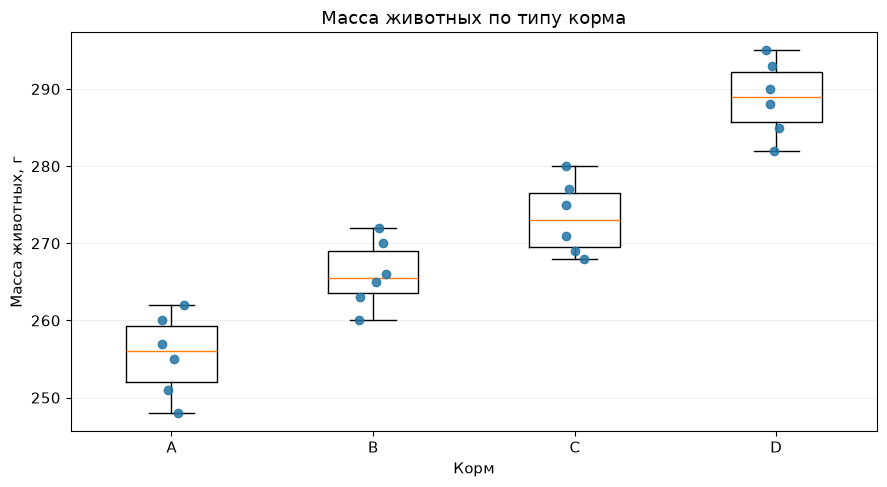

Левен: p-value=0.941694
ANOVA: F=49.924617; p-value=1.799725244e-09


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B     10.5 0.0064  2.6524 18.3476   True
     A      C  17.8333    0.0  9.9858 25.6809   True
     A      D  33.3333    0.0 25.4858 41.1809   True
     B      C   7.3333 0.0723 -0.5142 15.1809  False
     B      D  22.8333    0.0 14.9858 30.6809   True
     C      D     15.5 0.0001  7.6524 23.3476   True
----------------------------------------------------
Наибольшее выборочное среднее у корма D


In [5]:
groups = {
    'A': np.array([251,262,248,255,260,257]),
    'B': np.array([263,270,265,272,260,266]),
    'C': np.array([268,275,271,280,277,269]),
    'D': np.array([282,290,285,295,288,293]),
}
fig, ax = plt.subplots()
ax.boxplot(list(groups.values()), tick_labels=list(groups))
np.random.seed(42)
for pos, (name, values) in enumerate(groups.items(), start=1):
    ax.scatter(pos + np.random.uniform(-0.07, 0.07, len(values)), values,
               color='#2474a5', alpha=0.85, zorder=3)
    print(f'Корм {name}: среднее={values.mean():.3f} г; p Шапиро={stats.shapiro(values).pvalue:.6f}')
ax.set(xlabel='Корм', ylabel='Масса животных, г', title='Масса животных по типу корма')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
lev = stats.levene(*groups.values(), center='median')
anova = stats.f_oneway(*groups.values())
print(f'Левен: p-value={lev.pvalue:.6f}')
print(f'ANOVA: F={anova.statistic:.6f}; p-value={anova.pvalue:.10g}')
if anova.pvalue < alpha:
    values = np.concatenate(list(groups.values()))
    labels = np.repeat(list(groups), [len(v) for v in groups.values()])
    tukey = pairwise_tukeyhsd(values, labels, alpha=alpha)
    print(tukey)
print('Наибольшее выборочное среднее у корма', max(groups, key=lambda k: groups[k].mean()))

**Вывод:** проверки Шапиро–Уилка по группам и Левена не выявляют нарушений предпосылок, ANOVA показывает различие средних масс. Корм D даёт наибольшую среднюю массу (288,83 г), а Tukey HSD подтверждает его отличие от каждого из остальных кормов при семейном уровне ошибки 0,05; в данном эксперименте он наиболее эффективен по итоговой массе.

### Задание 6. A/B-тест по конверсии

Проводится A/B-тест на лендинге. В контрольной группе из 1000 пользователей конверсий 85, в тестовой группе из 1000 пользователей конверсий 120.

**Что сделать:**
- постройте 95% доверительные интервалы Уилсона для конверсии каждой группы;
- проверьте, значимо ли различаются конверсии (критерий хи-квадрат на таблице 2x2 или z-тест для двух долей) при $\alpha = 0.05$;
- постройте бутстрэп-интервал для разности конверсий (тест минус контроль);
- сделайте вывод, стоит ли выкатывать тестовый вариант.

**Выведите на экран:** границы интервалов Уилсона по группам, статистику и p-value выбранного теста, границы бутстрэп-интервала для разности и точечную разность конверсий.

In [6]:
conv_c, n_c = 85, 1000
conv_v, n_v = 120, 1000
pc, pv = conv_c/n_c, conv_v/n_v
ci_c = proportion_confint(conv_c, n_c, alpha=alpha, method='wilson')
ci_v = proportion_confint(conv_v, n_v, alpha=alpha, method='wilson')
z, p = proportions_ztest([conv_v, conv_c], [n_v, n_c], alternative='two-sided')
print(f'Контроль: конверсия={pc:.4f}; 95% ДИ Уилсона=[{ci_c[0]:.6f}; {ci_c[1]:.6f}]')
print(f'Тест: конверсия={pv:.4f}; 95% ДИ Уилсона=[{ci_v[0]:.6f}; {ci_v[1]:.6f}]')
print(f'z-тест долей: z={z:.6f}; двустороннее p-value={p:.6f}')
# Ресемплинг 0/1-наблюдений внутри каждой группы: число единиц
# в бутстрэп-выборке точно имеет Binomial(n, p_hat). Это позволяет
# получить обычный непараметрический бутстрэп без хранения большой матрицы.
np.random.seed(42)
bootstrap_repeats = 100_000
boot_c = np.random.binomial(n_c, pc, size=bootstrap_repeats) / n_c
boot_v = np.random.binomial(n_v, pv, size=bootstrap_repeats) / n_v
boot_delta = boot_v - boot_c
ci_boot = np.quantile(boot_delta, [0.025, 0.975])
delta = pv - pc
print(f'Разность тест−контроль={delta:.6f} ({100*delta:.2f} п.п.)')
print(f'95% процентильный бутстрэп-ДИ (B={bootstrap_repeats}): [{ci_boot[0]:.6f}; {ci_boot[1]:.6f}]')
print(f'В процентных пунктах: [{100*ci_boot[0]:.2f}; {100*ci_boot[1]:.2f}]')

Контроль: конверсия=0.0850; 95% ДИ Уилсона=[0.069263; 0.103913]
Тест: конверсия=0.1200; 95% ДИ Уилсона=[0.101299; 0.141609]
z-тест долей: z=2.580322; двустороннее p-value=0.009871
Разность тест−контроль=0.035000 (3.50 п.п.)
95% процентильный бутстрэп-ДИ (B=100000): [0.009000; 0.062000]
В процентных пунктах: [0.90; 6.20]


**Вывод:** тестовый вариант повышает конверсию с 8,5% до 12,0% (на 3,5 процентного пункта); двусторонний тест значим при α = 0,05, а 95%-й бутстрэп-интервал разности целиком выше нуля. По критерию конверсии выкатка обоснована при корректной рандомизации и отсутствии ухудшения защитных метрик и экономики, данных о которых в условии нет.